In [139]:
##importing packages

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
from statsmodels.nonparametric.smoothers_lowess import lowess
from scipy.stats import ttest_ind
import statsmodels.formula.api as smf
from statsmodels.gam.api import GLMGam, BSplines
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.outliers_influence import variance_inflation_factor


In [140]:
#lets get this new dataset going
df = pd.read_stata("/Users/dustinh/Downloads/framingham.dta")

df
df.columns



Index(['sex', 'totchol', 'age', 'sysbp', 'diabp', 'cursmoke', 'cigpday', 'bmi',
       'diabetes', 'bpmeds', 'heartrte', 'glucose', 'prevchd', 'prevap',
       'prevmi', 'prevstrk', 'prevhyp', 'death', 'angina', 'hospmi', 'mi_fchd',
       'anychd', 'stroke', 'cvd', 'hyperten', 'timeap', 'timemi', 'timemifc',
       'timechd', 'timestrk', 'timecvd', 'timedth', 'timehyp', 'bmicat',
       'agecat', 'obese_normal'],
      dtype='object')

In [141]:
#lets fit our first logistic regression
#first step is using death as y values and BMI was our initial x value

logistic_model = smf.logit('death ~ bmi', data=df).fit()


print(logistic_model.summary())

Optimization terminated successfully.
         Current function value: 0.641267
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:                  death   No. Observations:                 4415
Model:                          Logit   Df Residuals:                     4413
Method:                           MLE   Df Model:                            1
Date:                Sun, 11 Oct 2026   Pseudo R-squ.:                0.007760
Time:                        16:54:46   Log-Likelihood:                -2831.2
converged:                       True   LL-Null:                       -2853.3
Covariance Type:            nonrobust   LLR p-value:                 2.841e-11
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -1.9496      0.203     -9.612      0.000      -2.347      -1.552
bmi            0.0509      0.

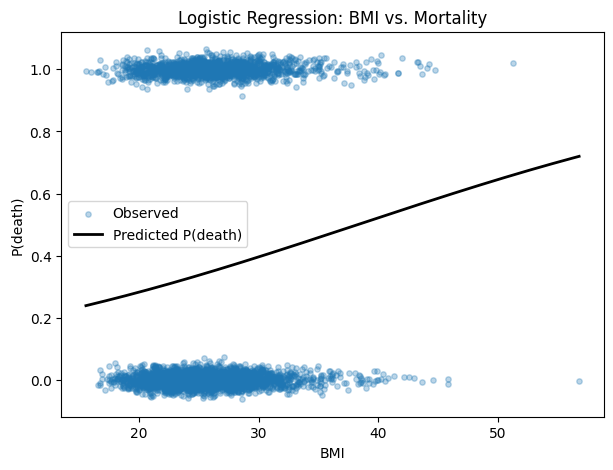

In [142]:
#I want to visualize this model


# generate a range of BMI values to plot the smooth curve
bmi_range = np.linspace(df['bmi'].min(), df['bmi'].max(), 200)
pred_df = pd.DataFrame({'bmi': bmi_range})
pred_probs = logistic_model.predict(pred_df)

fig, ax = plt.subplots(figsize=(7, 5))

jitter = np.random.normal(0, 0.02, size=len(df))
ax.scatter(df['bmi'], df['death'] + jitter, alpha=0.3, s=15, label='Observed')

# predicted probability curve
ax.plot(bmi_range, pred_probs, color='black', linewidth=2, label='Predicted P(death)')

ax.set_xlabel('BMI')
ax.set_ylabel('P(death)')
ax.set_title('Logistic Regression: BMI vs. Mortality')
ax.legend()
plt.show()





In [143]:
#this question is a little tricky. It is asking for a 5 unit change in BMI
#also, for whatever reason my code seems to only show .975 CI? lets chagne that 
#looks like the cont_int() defaults at a .95 CI


coef = logistic_model.params['bmi']
ci_low, ci_high = logistic_model.conf_int().loc['bmi']

# scale to a 5-unit change
coef_5 = coef * 5
ci_low_5 = ci_low * 5
ci_high_5 = ci_high * 5

# exponentiate to get odds ratio
or_5 = np.exp(coef_5)
ci_5 = np.exp([ci_low_5, ci_high_5])

print(f"OR for 5-unit BMI increase: {or_5:.3f}")
print(f"95% CI: ({ci_5[0]:.3f}, {ci_5[1]:.3f})")


OR for 5-unit BMI increase: 1.290
95% CI: (1.196, 1.391)


In [144]:
#now we are bringing in BMI squared

df['bmi_squared']= df['bmi'] ** 2

#now we are bringing in our BMI squared value to compare the results:

logistic_model_bmi_agesqared = smf.logit('death ~ bmi + bmi_squared', data=df).fit()

print(logistic_model_bmi_agesqared.summary())

Optimization terminated successfully.
         Current function value: 0.641249
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:                  death   No. Observations:                 4415
Model:                          Logit   Df Residuals:                     4412
Method:                           MLE   Df Model:                            2
Date:                Sun, 11 Oct 2026   Pseudo R-squ.:                0.007787
Time:                        16:54:46   Log-Likelihood:                -2831.1
converged:                       True   LL-Null:                       -2853.3
Covariance Type:            nonrobust   LLR p-value:                 2.240e-10
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      -1.6476      0.795     -2.073      0.038      -3.206      -0.090
bmi             0.0288    

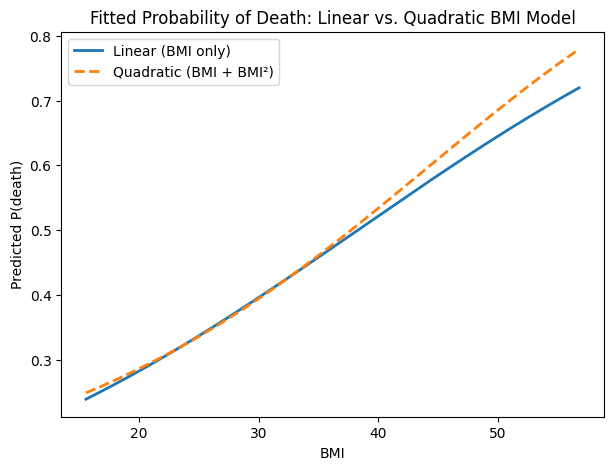

In [145]:

# we we need a add both models together on a plot
bmi_range = np.linspace(df['bmi'].min(), df['bmi'].max(), 200)
pred_df = pd.DataFrame({'bmi': bmi_range, 'bmi_squared': bmi_range**2})

# get predicted probabilities from both models
pred_probs_linear = logistic_model.predict(pred_df)
pred_probs_quad = logistic_model_bmi_agesqared.predict(pred_df)  # adjust name if yours differs

fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(bmi_range, pred_probs_linear, color='tab:blue', linestyle='-',
        linewidth=2, label='Linear (BMI only)')
ax.plot(bmi_range, pred_probs_quad, color='tab:orange', linestyle='--',
        linewidth=2, label='Quadratic (BMI + BMI²)')

ax.set_xlabel('BMI')
ax.set_ylabel('Predicted P(death)')
ax.set_title('Fitted Probability of Death: Linear vs. Quadratic BMI Model')
ax.legend()
plt.show()

In [146]:
#now we need to determine the impacts of 

params = logistic_model_bmi_agesqared.params  # use your actual model variable name

def log_odds(bmi):
    return params['Intercept'] + params['bmi']*bmi + params['bmi_squared']*bmi**2

# 20 to 25
log_or_20_25 = log_odds(25) - log_odds(20)
or_20_25 = np.exp(log_or_20_25)

# 25 to 30
log_or_30_35 = log_odds(35) - log_odds(30)
or_30_35 = np.exp(log_or_30_35)

print(f"OR for BMI 20 - 25: {or_20_25:.3f}")
print(f"OR for BMI 30 - 35: {or_30_35:.3f}")


OR for BMI 20 - 25: 1.262
OR for BMI 30 - 35: 1.313


/var/folders/r9/024r7wqn2kz5lxf3czsr79851408l0/T/ipykernel_7077/2820947419.py:17: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([male_bmi, female_bmi], labels=['Male', 'Female'])


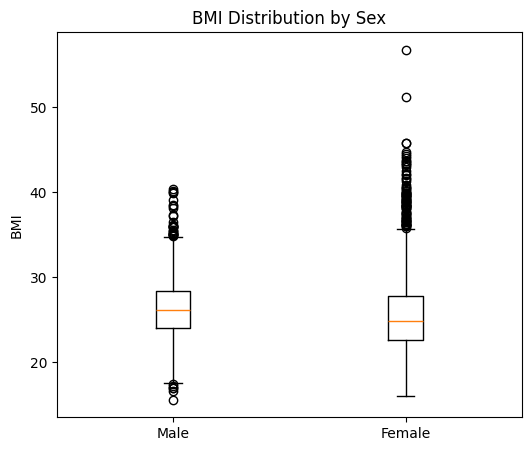

In [147]:
#now we need to make an indicator variable for sex

# check unique values first to confirm coding
df['sex'].value_counts()

#now lets make an indicator variable for female to either be 1 or 0

df['Female'] = (df['sex'] == 2).astype(int)

#now lets me a box polot 

fig, ax = plt.subplots(figsize=(6, 5))

male_bmi = df.loc[df['Female'] == 0, 'bmi'].dropna()
female_bmi = df.loc[df['Female'] == 1, 'bmi'].dropna()

ax.boxplot([male_bmi, female_bmi], labels=['Male', 'Female'])
ax.set_ylabel('BMI')
ax.set_title('BMI Distribution by Sex')
plt.show()


In [148]:
#now we need to see if there is an association between sex and death


sex_logistic = smf.logit('death ~ bmi + Female', data=df).fit()




print(sex_logistic.summary())



Optimization terminated successfully.
         Current function value: 0.629789
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:                  death   No. Observations:                 4415
Model:                          Logit   Df Residuals:                     4412
Method:                           MLE   Df Model:                            2
Date:                Sun, 11 Oct 2026   Pseudo R-squ.:                 0.02552
Time:                        16:54:46   Log-Likelihood:                -2780.5
converged:                       True   LL-Null:                       -2853.3
Covariance Type:            nonrobust   LLR p-value:                 2.374e-32
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -1.5139      0.210     -7.220      0.000      -1.925      -1.103
bmi            0.0474      0.

In [149]:
#now we need to add the interaction term where my female is multiplied by bmi

interaction_model_bmi_sex = smf.logit('death ~ bmi * Female', data=df).fit()
print(interaction_model_bmi_sex.summary())


np.exp(0.0575) 

Optimization terminated successfully.
         Current function value: 0.628417
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:                  death   No. Observations:                 4415
Model:                          Logit   Df Residuals:                     4411
Method:                           MLE   Df Model:                            3
Date:                Sun, 11 Oct 2026   Pseudo R-squ.:                 0.02764
Time:                        16:54:46   Log-Likelihood:                -2774.5
converged:                       True   LL-Null:                       -2853.3
Covariance Type:            nonrobust   LLR p-value:                 5.617e-34
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.5101      0.355     -1.436      0.151      -1.206       0.186
bmi            0.0091      0.

np.float64(1.0591852706547322)

In [150]:
#now we are making three differnt models with three differnt versions of age

#Continuous age
model_age_continuous = smf.logit('death ~ age', data=df).fit()

#Age category treated as continuous/ordinal
model_agecat_ordinal = smf.logit('death ~ agecat', data=df).fit()

# 3. Age category treated as categorical/indicator
model_agecat_indicator = smf.logit('death ~ C(agecat)', data=df).fit()

df['agecat'].nunique()

df.groupby('agecat')['age'].agg(['min', 'max', 'count'])


Optimization terminated successfully.
         Current function value: 0.553259
         Iterations 6
Optimization terminated successfully.
         Current function value: 0.562985
         Iterations 6
Optimization terminated successfully.
         Current function value: 0.562253
         Iterations 6


,min,max,count
agecat,,,
1.0,32.0,39.0,559
2.0,40.0,49.0,1692
3.0,50.0,59.0,1399
4.0,60.0,70.0,784


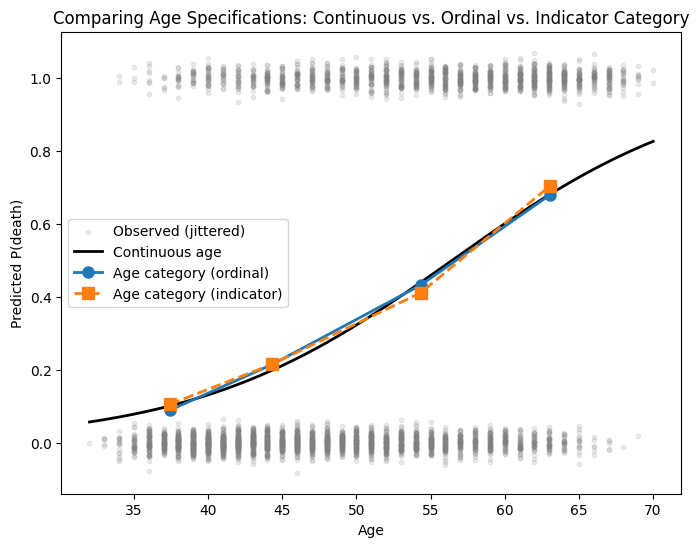

In [151]:
#now lets plot
#model 1
age_range = np.linspace(df['age'].min(), df['age'].max(), 200)
pred_probs_cont = model_age_continuous.predict(pd.DataFrame({'age': age_range}))

#model 2
agecat_levels = sorted(df['agecat'].dropna().unique())
pred_df_cat = pd.DataFrame({'agecat': agecat_levels})

pred_probs_ordinal = model_agecat_ordinal.predict(pred_df_cat)
pred_probs_indicator = model_agecat_indicator.predict(pred_df_cat)

# use each category's mean age so points land in the right spot on the age x-axis
agecat_age_mean = df.groupby('agecat')['age'].mean().loc[agecat_levels]

fig, ax = plt.subplots(figsize=(8, 6))

# observed data, jittered so 0/1 points aren't all stacked
jitter = np.random.normal(0, 0.02, size=len(df))
ax.scatter(df['age'], df['death'] + jitter, alpha=0.15, s=10, color='gray', label='Observed (jittered)')

# three model predictions overlaid
ax.plot(age_range, pred_probs_cont, color='black', linewidth=2, label='Continuous age')
ax.plot(agecat_age_mean, pred_probs_ordinal, 'o-', color='tab:blue', markersize=8, linewidth=2, label='Age category (ordinal)')
ax.plot(agecat_age_mean, pred_probs_indicator, 's--', color='tab:orange', markersize=8, linewidth=2, label='Age category (indicator)')

ax.set_xlabel('Age')
ax.set_ylabel('Predicted P(death)')
ax.set_title('Comparing Age Specifications: Continuous vs. Ordinal vs. Indicator Category')
ax.legend()
plt.show()

In [152]:
print(model_age_continuous.aic, model_age_continuous.llf)
print(model_agecat_ordinal.aic, model_agecat_ordinal.llf)
print(model_agecat_indicator.aic, model_agecat_indicator.llf)


4910.299217109911 -2453.1496085549556
4996.553232656554 -2496.276616328277
4994.061733163091 -2493.0308665815455


In [153]:
#ok now we are fitting a new model to determine if age * bmi is an effect modifer of death

#fist lets do our interaction
interaction_model_bmi_age = smf.logit('death ~ bmi * agecat', data=df).fit()

#now lets do no interaction
no_interaction_model_bmi_age = smf.logit('death ~ bmi + agecat', data=df).fit()


Optimization terminated successfully.
         Current function value: 0.561077
         Iterations 6
Optimization terminated successfully.
         Current function value: 0.561082
         Iterations 6


In [154]:
#now lets run summaries
interaction_model_bmi_age.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                  death   No. Observations:                 4415
Model:                          Logit   Df Residuals:                     4411
Method:                           MLE   Df Model:                            3
Date:                Sun, 11 Oct 2026   Pseudo R-squ.:                  0.1318
Time:                        16:54:46   Log-Likelihood:                -2477.2
converged:                       True   LL-Null:                       -2853.3
Covariance Type:            nonrobust   LLR p-value:                9.284e-163
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -3.9313      0.754     -5.211      0.000      -5.410      -2.453
bmi            0.0237      0.029      0.819      0.413      -0.033       0.080
agecat         0.9552      0.261      3.659      0.000       0.444       1.467
bmi:agecat     0.0021      0.010      0.212      0.832      -0.017       0.022
==============================================================================
"""

In [155]:

no_interaction_model_bmi_age.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                  death   No. Observations:                 4415
Model:                          Logit   Df Residuals:                     4412
Method:                           MLE   Df Model:                            2
Date:                Sun, 11 Oct 2026   Pseudo R-squ.:                  0.1318
Time:                        16:54:46   Log-Likelihood:                -2477.2
converged:                       True   LL-Null:                       -2853.3
Covariance Type:            nonrobust   LLR p-value:                4.333e-164
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -4.0830      0.242    -16.852      0.000      -4.558      -3.608
bmi            0.0296      0.008      3.516      0.000       0.013       0.046
agecat         1.0099      0.042     24.296      0.000       0.928       1.091
==============================================================================
"""

In [156]:
#ok now we are brinigng int all together and building out models in incrasing complexity until we find the best one

#lets start w the most basic: death ~ bmi (already done)
logistic_model
logistic_model.summary()

#now we are adding continoues age 
model_bmi_age = smf.logit('death ~ bmi + age', data=df).fit()
model_bmi_age.summary()

#now we add the interaction between bmi and age

model_bmi_age_int = smf.logit('death ~ bmi * age', data=df).fit()
model_bmi_age_int.summary()

#now we add sex value

model_bmi_age_sex = smf.logit('death ~ bmi + age + Female', data=df).fit()
model_bmi_age_sex.summary()

#now we add control for age

model_full = smf.logit('death ~ bmi + age + Female + bmi:Female', data=df).fit()



Optimization terminated successfully.
         Current function value: 0.551628
         Iterations 6
Optimization terminated successfully.
         Current function value: 0.551599
         Iterations 6
Optimization terminated successfully.
         Current function value: 0.535575
         Iterations 6
Optimization terminated successfully.
         Current function value: 0.535536
         Iterations 6


In [157]:
model_bmi_age_sex.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                  death   No. Observations:                 4415
Model:                          Logit   Df Residuals:                     4411
Method:                           MLE   Df Model:                            3
Date:                Sun, 11 Oct 2026   Pseudo R-squ.:                  0.1713
Time:                        16:54:46   Log-Likelihood:                -2364.6
converged:                       True   LL-Null:                       -2853.3
Covariance Type:            nonrobust   LLR p-value:                1.339e-211
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -6.8905      0.317    -21.758      0.000      -7.511      -6.270
bmi            0.0252      0.009      2.904      0.004       0.008       0.042
age            0.1187      0.005     25.988      0.000       0.110       0.128
Female        -0.8488      0.072    -11.730      0.000      -0.991      -0.707
==============================================================================
"""

In [158]:
model_full.summary()

np.exp(-0.8488)

np.float64(0.4279281377289486)

In [159]:
#building a new logistic regression with all models


full_model_all_variables = smf.logit('death ~ bmi + Female + age + cursmoke + cigpday + obese_normal + totchol + hyperten + diabetes + prevchd + prevmi + prevstrk', data=df).fit()

full_model_all_variables.summary()

Optimization terminated successfully.
         Current function value: 0.488790
         Iterations 6


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                  death   No. Observations:                 2468
Model:                          Logit   Df Residuals:                     2455
Method:                           MLE   Df Model:                           12
Date:                Sun, 11 Oct 2026   Pseudo R-squ.:                  0.2298
Time:                        16:54:46   Log-Likelihood:                -1206.3
converged:                       True   LL-Null:                       -1566.3
Covariance Type:            nonrobust   LLR p-value:                2.486e-146
================================================================================
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       -7.1269      0.655    -10.883      0.000      -8.410      -5.843
bmi             -0.0238      0.023     -1.043      0.297      -0.069       0.021
Female          -0.5952      0.112     -5.334      0.000      -0.814      -0.376
age              0.1333      0.007     19.046      0.000       0.120       0.147
cursmoke         0.0430      0.162      0.266      0.790      -0.274       0.360
cigpday          0.0283      0.007      4.161      0.000       0.015       0.042
obese_normal     0.7409      0.265      2.793      0.005       0.221       1.261
totchol          0.0005      0.001      0.402      0.688      -0.002       0.003
hyperten        -0.0741      0.121     -0.614      0.539      -0.311       0.162
diabetes         1.6145      0.351      4.597      0.000       0.926       2.303
prevchd          0.5979      0.337      1.775      0.076      -0.062       1.258
prevmi           0.9711      0.537      1.807      0.071      -0.082       2.024
prevstrk         1.0945      0.607      1.803      0.071      -0.095       2.284
================================================================================
"""

In [160]:
#ok now we need to write code to see how much colinnearity there is between each coefficent
#thankfully statsmodels has a perfect little package for this


# use the exact design matrix statsmodels built from your formula
X = full_model_all_variables.model.exog
vif_data = pd.DataFrame({
    'Variable': full_model_all_variables.model.exog_names,
    'VIF': [variance_inflation_factor(X, i) for i in range(X.shape[1])]
})
print(vif_data)


        Variable       VIF
0      Intercept  1.000000
1            bmi  5.328300
2         Female  1.182896
3            age  1.234530
4       cursmoke  2.492279
5        cigpday  2.601267
6   obese_normal  5.249405
7        totchol  1.112036
8       hyperten  1.126694
9       diabetes  1.029333
10       prevchd  1.969318
11        prevmi  1.939427
12      prevstrk  1.007116


In [162]:
#now we are going to do forward model select
#i am going to do this one by one to compare p values and AIC for practice
#in future versions, I think i will just use a for loop

null_model = smf.logit('death ~ 1', data=df).fit()
print(null_model.aic)

m_bmi = smf.logit('death ~ bmi', data=df).fit()
print(m_bmi.aic, m_bmi.pvalues['bmi'])


#actually, im realizing this is going to take too long. I think we should usea for loop


candidates = ['bmi', 'Female', 'age', 'cursmoke', 'cigpday', 'obese_normal',
              'totchol', 'hyperten', 'diabetes', 'prevchd', 'prevmi', 'prevstrk']

selected = []
remaining = candidates.copy()
current_aic = smf.logit('death ~ 1', data=df).fit(disp=0).aic

while remaining:
    aic_results = []
    for var in remaining:
        formula = 'death ~ ' + ' + '.join(selected + [var])
        model = smf.logit(formula, data=df).fit(disp=0)
        aic_results.append((model.aic, var))

    aic_results.sort()
    best_aic, best_var = aic_results[0]

    if best_aic < current_aic:
        selected.append(best_var)
        remaining.remove(best_var)
        current_aic = best_aic
        print(f"Added '{best_var}' AIC = {best_aic:.2f}")
    else:
        break

print("\nFinal selected variables (forward):", selected)
final_model_forward = smf.logit('death ~ ' + ' + '.join(selected), data=df).fit()
print(final_model_forward.summary())



Optimization terminated successfully.
         Current function value: 0.647181
         Iterations 4
5741.200866552723
Optimization terminated successfully.
         Current function value: 0.641267
         Iterations 5
5666.388136746582 3.4248082453025686e-11
Added 'obese_normal' AIC = 3146.27
Added 'age' AIC = 2635.45
Added 'cigpday' AIC = 2537.70
Added 'Female' AIC = 2502.14
Added 'totchol' AIC = 2473.91
Added 'diabetes' AIC = 2451.17
Added 'prevmi' AIC = 2436.74
Added 'prevchd' AIC = 2435.58
Added 'prevstrk' AIC = 2434.35

Final selected variables (forward): ['obese_normal', 'age', 'cigpday', 'Female', 'totchol', 'diabetes', 'prevmi', 'prevchd', 'prevstrk']
Optimization terminated successfully.
         Current function value: 0.489131
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:                  death   No. Observations:                 2468
Model:                          Logit   Df Residuals:               

In [164]:
#now lets do backwards using the for loop as well

selected = candidates.copy()  # start with all 12 variables
current_model = smf.logit('death ~ ' + ' + '.join(selected), data=df).fit(disp=0)
current_aic = current_model.aic

while len(selected) > 0:
    aic_results = []
    for var in selected:
        remaining_vars = [v for v in selected if v != var]
        formula = 'death ~ ' + ' + '.join(remaining_vars) if remaining_vars else 'death ~ 1'
        model = smf.logit(formula, data=df).fit(disp=0)
        aic_results.append((model.aic, var))

    aic_results.sort()
    best_aic, var_to_remove = aic_results[0]

    if best_aic < current_aic:
        selected.remove(var_to_remove)
        current_aic = best_aic
        print(f"Removed '{var_to_remove}' AIC = {best_aic:.2f}")
    else:
        break

print("\nFinal selected variables (backward):", selected)
final_model_backward = smf.logit('death ~ ' + ' + '.join(selected), data=df).fit()
print(final_model_backward.summary())


Removed 'cursmoke' AIC = 2436.74
Removed 'hyperten' AIC = 2435.12
Removed 'bmi' AIC = 2434.35

Final selected variables (backward): ['Female', 'age', 'cigpday', 'obese_normal', 'totchol', 'diabetes', 'prevchd', 'prevmi', 'prevstrk']
Optimization terminated successfully.
         Current function value: 0.489131
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:                  death   No. Observations:                 2468
Model:                          Logit   Df Residuals:                     2458
Method:                           MLE   Df Model:                            9
Date:                Sun, 11 Oct 2026   Pseudo R-squ.:                  0.2293
Time:                        16:58:03   Log-Likelihood:                -1207.2
converged:                       True   LL-Null:                       -1566.3
Covariance Type:            nonrobust   LLR p-value:                8.610e-149
                   coef    std er

In [ ]:
#ok now we are going to do stepeise
#seems like they are all going to have the same variables, p values and log likelihood

selected = candidates.copy()  # start with all 12 variables
current_model = smf.logit('death ~ ' + ' + '.join(selected), data=df).fit(disp=0)
current_aic = current_model.aic

while len(selected) > 0:
    aic_results = []
    for var in selected:
        remaining_vars = [v for v in selected if v != var]
        formula = 'death ~ ' + ' + '.join(remaining_vars) if remaining_vars else 'death ~ 1'
        model = smf.logit(formula, data=df).fit(disp=0)
        aic_results.append((model.aic, var))

    aic_results.sort()
    best_aic, var_to_remove = aic_results[0]

    if best_aic < current_aic:
        selected.remove(var_to_remove)
        current_aic = best_aic
        print(f"Removed '{var_to_remove}' AIC = {best_aic:.2f}")
    else:
        break

print("\nFinal selected variables (backward):", selected)
final_model_backward = smf.logit('death ~ ' + ' + '.join(selected), data=df).fit()
print(final_model_backward.summary())


Removed 'cursmoke' AIC = 2436.74
Removed 'hyperten' AIC = 2435.12
Removed 'bmi' AIC = 2434.35

Final selected variables (backward): ['Female', 'age', 'cigpday', 'obese_normal', 'totchol', 'diabetes', 'prevchd', 'prevmi', 'prevstrk']
Optimization terminated successfully.
         Current function value: 0.489131
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:                  death   No. Observations:                 2468
Model:                          Logit   Df Residuals:                     2458
Method:                           MLE   Df Model:                            9
Date:                Sun, 11 Oct 2026   Pseudo R-squ.:                  0.2293
Time:                        16:59:14   Log-Likelihood:                -1207.2
converged:                       True   LL-Null:                       -1566.3
Covariance Type:            nonrobust   LLR p-value:                8.610e-149
                   coef    std er